In [1]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pywt
from matplotlib.font_manager import FontProperties
import pickle
import math
import scipy
import scipy.signal
import vector
import json
import zipfile
import os

%matplotlib inline 
#np.set_printoptions(threshold=np.inf)

# pd.set_option('display.max_columns', None) #原来中间会有部分列的显示被省略

In [2]:
def filters_main(spec,use_new=2):
    #comprehensive filters that handle the filter process
    #set use_new to 0 if use movemean 20pt, use_new to 1 if fir

    ## baseline 1
    # old mov_mean does not use
    # 输入一个list
    spec=np.array(spec)#转化成numpy形式
    if use_new == 1 or use_new == 2:
        baseline_1 = spec
    else:
        baseline_1 = spec

    ## filter
    if use_new == 2:
        filtered = filter_gaus(baseline_1)
    elif use_new == 0:
        # default 21pt filter
        filtered = filter_mov(baseline_1)

    ## baseline correction2
    if use_new == 1 or use_new == 2:
        out = filtered - matlab_percentile(filtered, 10)
        out[out < 0] = 0
    elif use_new == 0:
        filtered[filtered < 0] = 0
        out = filtered - filtered.min()

    out = out.tolist()
    #print(type(out)) = list
    #print(out) = []
    return(out)

def filter_gaus(input_spec,cycle=1):

    window = 100
    alpha = 6
    std = (window - 1) / (2 * alpha)
    b = scipy.signal.windows.gaussian(window, std, sym=True)
    b = b / sum(b)
    output_spec = np.convolve(input_spec, b,'same')
    for i in range(2, cycle + 1):
        output_spec = np.convolve(input_spec, b,'same')
    return(output_spec)



def filter_mov(input_spec, window=21, cycle=1):
    # input_spec is a 1d array
    # window is the width of the move mean
    # cycle is the repetive number
    use_old = 1
    if use_old != 0:
        MEAN_SIZE = window - 1
        for k in range(1,cycle+1):
            half = MEAN_SIZE/ 2
            npt=MEAN_SIZE+1
            lentmp1=len(input_spec)
            if half < 1:
                tmp =input_spec
            else:
                tmp=[]
                for i in range(0,lentmp1):
                    if i>=0 and i<=half-1 or i>=lentmp1-half-1 and  i<=lentmp1-1:
                        mean_value=math.floor(np.mean(input_spec[0:10]))
                        tmp.append((input_spec[i]-mean_value)/npt+mean_value)
                    else:
                        tmp.append(math.floor(np.mean(input_spec[i-10-1:i+10])))

                tmp = np.array(tmp)
            tmp=np.transpose(tmp)
            output_spec=tmp
    else:

        b = (1 / window) * np.ones(window)
        output_spec=np.convolve(input_spec,b,'same')
        for i in range(2,cycle+1):
            output_spec=np.convolve(input_spec,b,'same')

    return(output_spec)




def matlab_percentile(x, p):
    p = np.asarray(p, dtype=float)
    n = len(x)
    p = (p-50)*n/(n-1) + 50
    p = np.clip(p, 0, 100)
    baseline=np.percentile(x, p)
    return(baseline)

def get_spec_params(data,is_neg=0):
# is_neg=0时：正模式，输入一个参数正模式
    if is_neg: #负模式
        mass_calib_c0 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters_neg']['spec_parameters']['mass_calib_c0']['value']
        mass_calib_c1 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters_neg']['spec_parameters']['mass_calib_c1']['value']
        mass_calib_c2 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters_neg']['spec_parameters']['mass_calib_c2']['value']
        calib_mass_start = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters_neg']['spec_parameters']['calib_mass_start']['value']
    else: #正模式
        mass_calib_c0 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['spec_parameters']['mass_calib_c0']['value']
        mass_calib_c1 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['spec_parameters']['mass_calib_c1']['value']
        mass_calib_c2 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['spec_parameters']['mass_calib_c2']['value']
        calib_mass_start = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['spec_parameters']['calib_mass_start']['value']

    return(mass_calib_c0, mass_calib_c1, mass_calib_c2, calib_mass_start)

def Method1_get_filelist(path): #path = 'W:/study/PHD1/检测器tutorial/10.30数据/different_ppm_samePara/20PPM/'  # (一个文件夹)
    file_list = []
    for root, dirs, files in os.walk(path):
        for file in files:
            if 'mrz' in file:
                file_list.append(os.path.join('%s%s' % (root, file)))
  # file_list 是一个list
    return(file_list)
def load_mrz(name):  #filepath = 'W:/study/PHD1/检测器tutorial/10.30数据/different_ppm_samePara/500PPB/1.mrz' , type=mrz
    zfile = zipfile.ZipFile(name)   #zfile.namelist()={'arbitrary_2021_10_30_18_07_11_227.json'}
    if len(zfile.namelist()) ==1:
        for filenames in zfile.namelist():
            zfile.extract(filenames, path=os.getcwd())
            file = os.getcwd() + '/' + filenames
            with open(file, "r", encoding='utf-8') as fp:
                data = json.load(fp)
            if os.path.exists(file):  # 如果文件存在
                os.remove(file)
        return(data)
    
def process_mrz_data(data,use_new_filter=2):
    n=0
    while n<=(len(data['analysis']['scan_list'])-1):
        pt_per_th = data['analysis']['parameters_files']['static_parameters']['static_parameters']['pt_per_th']
        scan_speed = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['calib_parameters']['scan_speed']['value']
        if data['analysis']['scan_list'][n]['method_parameters']['polarity'] == "NEG":
            [mass_calib_c0, mass_calib_c1, mass_calib_c2, calib_mass_start] = get_spec_params(data, 1)
        else:
            [mass_calib_c0, mass_calib_c1, mass_calib_c2, calib_mass_start] = get_spec_params(data)

        if type(data['analysis']['scan_list'][n]['raw_data'][0])== "dict":
            print('data是字典结构，请重新调试程序')
            #data['analysis']['scan_list'][n]['filtered']={}
            data['analysis']['scan_list'][n]['mz'] = {}
            for len_data in range(0,len(data['analysis']['scan_list'][n]['data'])):
                if len(data['analysis']['scan_list'][n]['data'][0])==1:
                    if data['analysis']['scan_list'][n].__contains__('raw_counting_data') and data['analysis']['scan_list'][n].__contains__('raw_analog_data'):
                        # filtered the analog data
                        data['analysis']['scan_list'][n]['analog_filtered'] = filters_main(data['analysis']['scan_list'][n]['raw_analog_data'][0],use_new_filter)
                        data['analysis']['scan_list'][n]['analog_filtered'] = [data['analysis']['scan_list'][n]['analog_filtered']]


                if data['analysis']['scan_list'][n]['method_parameters'].__contains__('scan_mass_start') and calib_mass_start != data['analysis']['scan_list'][n]['method_parameters']['scan_mass_start']:
                    x0 = [i+pt_per_th * (data['analysis']['scan_list'][n]['method_parameters']['scan_mass_start']-calib_mass_start) for i in range(0,len_data)]
                    data['analysis']['scan_list'][n]['mz'] = np.polyval([mass_calib_c2, mass_calib_c1, mass_calib_c0], x0).tolist()
                    data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]

                else:
                    x0=[i for i in range(0,len_data)]
                    data['analysis']['scan_list'][n]['mz'] = np.polyval([mass_calib_c2, mass_calib_c1, mass_calib_c0], x0).tolist()
                    data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]


                # prepare the temp
                if data['analysis']['scan_list'][n]['spec_parameters'].__contains__('mass_temp_comp_c0') and data['analysis']['scan_list'][n]['spec_parameters'].__contains__('mass_temp_comp_c1') and data['analysis']['scan_list'][n]['spec_parameters'].__contains__('mass_temp_comp_c2') and data['analysis']['scan_list'][n]['spec_parameters'].__contains__('current_temperature') and data['analysis']['scan_list'][n]['spec_parameters'].__contains__('calib_temperature'):
                    if float(data['analysis']['config']['DataProcessing']['mass_temp_comp_enabled']) == 1:
                        t_c0 = data['analysis']['scan_list'][n]['spec_parameters']['mass_temp_comp_c0']
                        t_c1 = data['analysis']['scan_list'][n]['spec_parameters']['mass_temp_comp_c1']
                        t_c2 = data['analysis']['scan_list'][n]['spec_parameters']['mass_temp_comp_c2']
                        dt = data['analysis']['scan_list'][n]['spec_parameters']['current_temperature'] - data['analysis']['scan_list'][n]['spec_parameters']['calib_temperature']

                        data['analysis']['scan_list'][n]['mz'] = temp_correction(data['analysis']['scan_list'][n]['mz'],t_c0, t_c1, t_c2, dt)
                        data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]

        else:
            data['analysis']['scan_list'][n]['analog_filtered'] = filters_main(data['analysis']['scan_list'][n]['raw_data'], 2)
            data['analysis']['scan_list'][n]['analog_filtered'] = [data['analysis']['scan_list'][n]['analog_filtered']]
            #prepare the mz
            len_data=len(data['analysis']['scan_list'][n]['raw_data'])
            if data['analysis']['scan_list'][n]['method_parameters'].__contains__('scan_mass_start') and calib_mass_start != data['analysis']['scan_list'][n]['method_parameters']['scan_mass_start']:
                x0 = [i+pt_per_th * (data['analysis']['scan_list'][n]['method_parameters']['scan_mass_start']-calib_mass_start) for i in range(0,len_data)]
                data['analysis']['scan_list'][n]['mz'] = np.polyval([mass_calib_c2, mass_calib_c1, mass_calib_c0], x0).tolist()
                data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]
            else:
                x0=[i for i in range(0,len_data)]
                data['analysis']['scan_list'][n]['mz'] = np.polyval([mass_calib_c2, mass_calib_c1, mass_calib_c0], x0).tolist()
                data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]
        n=n+1
    return(data)
                                                        
                                                          
def baseline_delete_method2(raw_data_list):   #所有的数据 按照平均值的正负3倍std,速度很慢
    spec = np.array(raw_data_list)
    baseline = spec
    i = 0
    mean_base=[]
    std_base=[]
    while i < 3 :
        mean_base.append(np.mean(baseline))
        std_base.append(np.std(baseline))
        baseline = spec[np.where(spec<(mean_base[i] + 3*std_base[i]))]
        i = i+1
    if np.size(spec,0)==1:
        filterd_data = spec - np.mean(baseline) # [[class 'numpy.ndarray']]
    else:
        print('请检查raw_data维数')
    return (filterd_data) ## <class 'numpy.ndarray'>

In [3]:
import os

def Method1_get_filelist(path, file_extension='.mrz',file_start='NMS1-1'):
    file_list = []
    for root, dirs, files in os.walk(path):
        for file in files:
            if file.startswith(file_start) and file.endswith(file_extension):  # 检查文件名前缀和后缀
                file_list.append(os.path.join(root, file))
    return file_list
# Method1_get_filelist('D:/DATA/ZHY/cwt图像处理/2hg/')
# eg: Method1_get_filelist('E:/神经胶质瘤/HS_data_new/1/')


In [4]:
import os
import numpy as np
from scipy.linalg import expm, logm
import matplotlib.pyplot as plt

def process_files(folder_path):
    file_list = Method1_get_filelist(folder_path)
    spectrograms = []

# 创建一个用于存放图像的新文件夹
    output_folder = os.path.join(folder_path, 'SpectrogramsPlot')
    if not os.path.exists(output_folder):
        os.makedirs(output_folder)

    for name in file_list:
        data = load_mrz(name)
        data = process_mrz_data(data, use_new_filter=2)

        y_int = data['analysis']['scan_list'][0]['analog_filtered'][0]
        x_mz = data['analysis']['scan_list'][0]['mz'][0]

        plt.plot(x_mz, y_int)
        # 保存图像到新文件夹
        plt.savefig(os.path.join(output_folder, f'{os.path.basename(name)}_plot.svg'), format='svg')
        plt.close()  # 防止显示图像
        spectrogram = np.array([x_mz, y_int])
        spectrograms.append(spectrogram)
        
    return spectrograms


# folder_path = 'D:/DATA/ZHY/cwt图像处理/2hg/'
# spectrograms = process_files(folder_path)

In [5]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
def generate_spectrogram(spectrogram):
    """
    根据给定的质谱数据生成时频图。
    """
    # 信号强度
    signal_strength = spectrogram[1]

    # 连续小波变换参数
    wavelet = signal.ricker
    widths = np.linspace(1, 100, 80, dtype=int)

    # 进行连续小波变换
    cwt_matrix = signal.cwt(signal_strength, wavelet, widths)

    # 获取时间轴和频率轴
    time = spectrogram[0]
    return np.abs(cwt_matrix), time, widths

def plot_spectrogram(cwt_matrix, time, widths):
    """
    绘制时频图
    """
    plt.figure(figsize=(10, 6))
    plt.imshow(cwt_matrix, extent=[time.min(), time.max(), 100, 1], aspect='auto', vmin=cwt_matrix.min(), vmax=cwt_matrix.max())
    plt.colorbar()
    plt.xlabel('Time')
    plt.ylabel('Scale')
    plt.title('Continuous Wavelet Transform Spectrogram')
    plt.show()

#vmin=cwt_matrix.min(), vmax=cwt_matrix.max(): 
#这些参数设置颜色映射的最小值和最大值。
#它们被设置为cwt_matrix的最小值和最大值，颜色将代表矩阵中的最小值和最大值。


In [6]:
num_points = int(np.ceil((100 - 1) / 80)) + 1  # Covering the range from 1 to 100
widths = np.linspace(1, 100, num_points, dtype=int)
num_points 

3

In [7]:
def integrate_spectrograms(spectrograms):
    # 假设所有时频图都具有相同的维度
    integrated = np.stack([s[0] for s in spectrograms], axis=-1)
    return integrated
    
def batch_process(root_folder):
    '''
    最后生成的type(processed_samples)是list，长度是样本个数，139个
    processed_samples[i]是numpy.ndarray，np.shape是(99, 18229, 1)
    '''
    processed_samples = []
    expected_shape = (99, 18229)
    for folder in os.listdir(root_folder):
        folder_path = os.path.join(root_folder, folder)
        if os.path.isdir(folder_path):
            spectrograms = process_files(folder_path)
            processed_spectrograms = [generate_spectrogram(s) for s in spectrograms]

            integrated_spectrograms = integrate_spectrograms(processed_spectrograms)

            processed_samples.append(integrated_spectrograms)
    return processed_samples

# 使用批量处理函数
root_folder = 'F:\神经胶质瘤\HS_data_new_CWT' 
processed_samples = batch_process(root_folder)


In [8]:
np.shape(processed_samples[0])


(80, 18229, 1)

In [9]:
import pandas as pd
import re

# Excel文件路径
excel_path = 'F:/神经胶质瘤/HS_data_new/labellist.xlsx'

# 读取Excel文件
df = pd.read_excel(excel_path)

# 筛选第二列值为0或1的行
filtered_df = df[df.iloc[:, 1].isin([0, 1])]

# 将第一列转换为字符串
filtered_df.iloc[:, 0] = filtered_df.iloc[:, 0].astype(str)

# 按第一列字符串排序
sorted_df = filtered_df.sort_values(by=filtered_df.columns[0])

# 查看排序后的DataFrame
print(sorted_df)
labels = sorted_df.iloc[:,1].values

    序号（数据分析用）  IDH_status（0:wt; 1:mt; 2:N; 3:/）
76         10                                 1
56        100                                 0
105       101                                 1
57        102                                 0
106       103                                 1
..        ...                               ...
53         94                                 0
54         95                                 0
103        97                                 1
104        98                                 1
55         99                                 0

[123 rows x 2 columns]


C:\Users\Administrator\AppData\Local\Temp\ipykernel_22396\1698098488.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df.iloc[:, 0] = filtered_df.iloc[:, 0].astype(str)


In [10]:
processed_samples_array=np.array(processed_samples)
np.shape(processed_samples_array)
len(labels)

(123, 80, 18229, 1)

123

# CNN 模型

Epoch 1/10
311/311 [==============================] - 749s 2s/step - loss: 2.0762 - accuracy: 0.5949 - val_loss: 0.6784 - val_accuracy: 0.5968
Epoch 2/10
311/311 [==============================] - 858s 3s/step - loss: 0.6763 - accuracy: 0.6017 - val_loss: 0.6786 - val_accuracy: 0.5972
Epoch 3/10
311/311 [==============================] - 841s 3s/step - loss: 0.6690 - accuracy: 0.6028 - val_loss: 0.6754 - val_accuracy: 0.5960
Epoch 4/10
311/311 [==============================] - 875s 3s/step - loss: 0.6640 - accuracy: 0.6034 - val_loss: 0.6782 - val_accuracy: 0.5956
Epoch 5/10
311/311 [==============================] - 887s 3s/step - loss: 0.6554 - accuracy: 0.6045 - val_loss: 0.6785 - val_accuracy: 0.5968
Epoch 6/10
311/311 [==============================] - 964s 3s/step - loss: 0.6523 - accuracy: 0.6074 - val_loss: 0.6822 - val_accuracy: 0.5968
Epoch 7/10
311/311 [==============================] - 964s 3s/step - loss: 0.6436 - accuracy: 0.6155 - val_loss: 0.6807 - val_accuracy: 0.5940

<Figure size 1200x500 with 0 Axes>

<Axes: >

Text(0.5, 1.0, 'Model Accuracy')

Text(0.5, 0, 'Epoch')

Text(0, 0.5, 'Accuracy')

<Axes: >

Text(0.5, 1.0, 'Model Loss')

Text(0.5, 0, 'Epoch')

Text(0, 0.5, 'Loss')

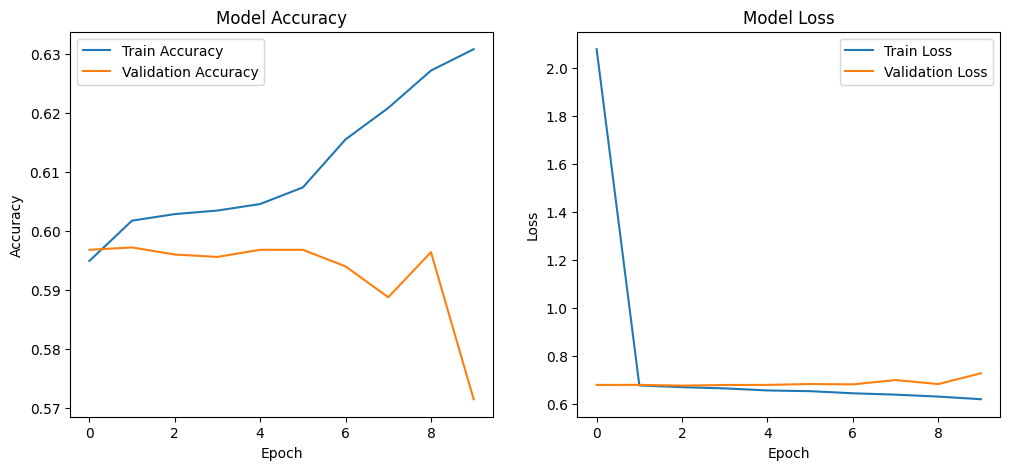

In [12]:
import numpy as np
from skimage.measure import block_reduce
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
def add_noise(sample, noise_level=0.01):
    noise = noise_level * np.random.normal(loc=0.0, scale=1.0, size=sample.shape)
    return sample + noise
def time_shift(sample, shift_max=50):
    shift = np.random.randint(-shift_max, shift_max)
    return np.roll(sample, shift, axis=1)

def frequency_mask(sample, mask_percentage=0.1):
    num_frequency = sample.shape[0]
    f = np.random.randint(0, num_frequency * (1 - mask_percentage))
    mask_end = int(f + num_frequency * mask_percentage)
    sample[f:mask_end, :] = 0
    return sample

def time_scale(sample, scale=1.2):
    from scipy.ndimage import zoom
    scaled = zoom(sample, (1, scale), order=1)
    if scale > 1:
        return scaled[:, :sample.shape[1]]
    else:
        pad_width = sample.shape[1] - scaled.shape[1]
        return np.pad(scaled, ((0, 0), (0, pad_width)), mode='constant', constant_values=0)

# 函数：使用池化减少样本维度
def reduce_dimensions(sample, pool_size=(2, 20)):
    return block_reduce(sample, block_size=pool_size, func=np.mean)

# 函数：数据增强
def augment_data(samples, num_augments_per_sample=100):
    augmented_samples = []
    for sample in samples:
        for _ in range(num_augments_per_sample):
            sample_aug = sample.copy()
            if np.random.rand() < 0.5:
                sample_aug = time_shift(sample_aug)
            if np.random.rand() < 0.5:
                sample_aug = frequency_mask(sample_aug)
            if np.random.rand() < 0.5:
                sample_aug = time_scale(sample_aug)
            noisy_sample = add_noise(sample_aug)
            augmented_samples.append(noisy_sample)
    return np.array(augmented_samples)

# 假设 processed_samples_array 是原始的时频图数据
pooled_samples = np.array([reduce_dimensions(sample.squeeze()) for sample in processed_samples_array])
augmented_samples = augment_data(pooled_samples)

# 合并原始和增强的样本及其标签
total_samples = np.concatenate([pooled_samples, augmented_samples], axis=0)
total_labels = np.concatenate([labels, np.tile(labels, len(augmented_samples) // len(labels))], axis=0)

# 划分数据集
train_samples, test_samples, train_labels, test_labels = train_test_split(
    total_samples, total_labels, test_size=0.2, random_state=42)

#### 2. 构建更复杂的CNN模型
def build_cnn_model(input_shape):
    model = Sequential([
        Conv2D(64, (3, 3), padding='same', activation='relu', input_shape=input_shape),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Conv2D(128, (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Conv2D(256, (3, 3), padding='same', activation='relu'),
        Dropout(0.5),
        Flatten(),
        Dense(256, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# 获取样本的维度并初始化模型
input_shape = (train_samples.shape[1], train_samples.shape[2], 1)
model = build_cnn_model(input_shape)

# 模型训练
history = model.fit(train_samples, train_labels, epochs=10, batch_size=32, validation_data=(test_samples, test_labels))

#### 3. 可视化模型的训练结果
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [13]:
from tensorflow.keras.utils import plot_model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

def build_large_input_cnn(input_shape):
    model = Sequential([
        Conv2D(32, kernel_size=(5, 5), activation='relu', input_shape=input_shape),
        MaxPooling2D(pool_size=(2, 2)),
        Conv2D(64, kernel_size=(5, 5), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),
        Conv2D(128, kernel_size=(3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Flatten(),
        Dense(256, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')  # 假设是二分类问题
    ])
    
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# 假设你的输入尺寸是 (50, 912, 1)
model = build_large_input_cnn((50, 912, 1))
model.summary()
# 假设你的模型已经通过build_cnn_model函数构建并赋值给了model变量
plot_model(model, to_file='model.png', show_shapes=True, show_layer_names=True)

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_3 (Conv2D)           (None, 46, 908, 32)       832       
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 23, 454, 32)       0         
 g2D)                                                            
                                                                 
 conv2d_4 (Conv2D)           (None, 19, 450, 64)       51264     
                                                                 
 max_pooling2d_3 (MaxPoolin  (None, 9, 225, 64)        0         
 g2D)                                                            
                                                                 
 dropout_2 (Dropout)         (None, 9, 225, 64)        0         
                                                                 
 conv2d_5 (Conv2D)           (None, 7, 223, 128)      

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# 预测测试集
test_predictions = model.predict(test_samples)
test_predictions = (test_predictions > 0.5).astype(int)  # 对于sigmoid输出，使用0.5作为阈值

# 创建混淆矩阵
cm = confusion_matrix(test_labels, test_predictions)

# 绘制矩阵图
plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot=True, fmt="d", linewidths=.5, square = True, cmap = 'Blues')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Confusion Matrix', size = 15)
plt.show()

In [ ]:
len(augmented_samples) 